# IoT 트래픽 분류 모델 성능 향상 v3 — FT-Transformer (Lane C)
**작성자**: 2026154001 정용석  
**연구 과제**: ISCX VPN/Non-VPN 다중 트래픽 분류를 위한 피처 토크나이저 기반 트랜스포머(FT-Transformer) 모델 설계 및 엄격한 검증셋 벤치마킹

---

### 연구 개요 및 Lane C 방법론
1. **연구 배경 및 문제 정의**:
   - v1의 전통적 다층 퍼셉트론(MLP)은 14개 트래픽 클래스 간 불균형(최대 12:1)과 연속형 네트워크 통계 특성 간의 복잡한 비선형 상호작용을 충분히 모델링하지 못하여 성능이 제한적이었습니다.
   - 이에 Lane C에서는 Gorishniy et al. (NeurIPS 2021)의 **FT-Transformer (Feature Tokenizer + Transformer)** 아키텍처를 도입하였습니다. 각 수치형 특성을 연속형 사상(Feature Tokenizer)을 통해 고차원 임베딩 토큰으로 변환하고, Multi-Head Self-Attention을 통해 특성 간 전역적 상호작용(Feature Interaction)을 심층 학습합니다.
2. **엄격한 프로토콜 준수 (Locked Protocol)**:
   - **데이터셋 및 분할**: `TimeBasedFeatures-Dataset-15s.arff` 데이터셋에서 중복 제거(18,758 -> 18,074행) 후, v1/v2와 동일한 60 / 20 / 20 Stratified Split (`random_state=42`) 적용.
   - **v2 특성 엔지니어링 (75차원)**: 왜도 완화 `log1p` 변환(23개), 패킷당 바이트비, 순방향/역방향 간격비, 활성/유휴비, Flow/Active/Idle 변동계수(CV), 음수 플래그(23개).
   - **Data Leakage 방지 원칙**: `RobustScaler` 및 `SelectFromModel` (ExtraTrees median threshold -> 38개 특성)은 오직 **Train 셋에만 피팅**.
   - **검증 전용 튜닝 원칙 (Val Tuning ONLY)**: 데이터 누수를 원천 방지하기 위해 **Test 셋 접근을 절대 금지 (MUST NOT access Test)**. 모든 모델 평가 및 하이퍼파라미터 튜닝은 Validation 셋으로만 수행.
3. **실험 및 보고 기준**:
   - 고정 시드 3개 (`[42, 1004, 2026]`) 3-Run 반복 실험.
   - 표본표준편차 $n=3$, $ddof=1$ 기준 Validation 정확도(Accuracy) 및 매크로 F1(Macro-F1) 보고.
   - `val_metrics.json` 생성 및 로컬 커밋 완료.

In [1]:
import os
import warnings
os.environ['PYTHONHASHSEED'] = '42'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import urllib.request
import zipfile
import hashlib
from scipy.io import arff
import matplotlib.pyplot as plt
import json
import time
import copy

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Global reproducibility
torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(4)

print(f"NumPy: {np.__version__}, Pandas: {pd.__version__}, Scikit-Learn: {sklearn.__version__}, PyTorch: {torch.__version__}")
device = torch.device('cpu')
print(f"Execution Device: {device} (Intra-op Threads: {torch.get_num_threads()})")

NumPy: 2.3.5, Pandas: 3.0.5, Scikit-Learn: 1.9.0, PyTorch: 2.13.0
Execution Device: cpu (Intra-op Threads: 4)


## 1. 데이터 다운로드 및 무결성 검증
ISCX VPN-nonVPN 데이터셋을 다운로드하고 MD5 해시를 비교하여 데이터 무결성을 검증합니다.

In [2]:
possible_paths = [
    "Yeni_klasor_temp/Yeni klasör/IscxDataset/ScenarioB/TimeBasedFeatures-Dataset-15s.arff",
    "../Yeni_klasor_temp/Yeni klasör/IscxDataset/ScenarioB/TimeBasedFeatures-Dataset-15s.arff",
    "dataset.zip",
    "../dataset.zip"
]

data_path = None
for p in possible_paths[:2]:
    if os.path.exists(p):
        data_path = p
        break

if data_path is None:
    zip_path = "dataset.zip" if os.path.exists("dataset.zip") else "../dataset.zip"
    if not os.path.exists(zip_path):
        url = "https://raw.githubusercontent.com/Muzafferrr/DL-ML-with-Brasil-VPN-NON-VPN-Dataset/main/DL%26ML%20with%20VPNNON-VPN%20Dataset.zip"
        print("Downloading dataset...")
        urllib.request.urlretrieve(url, "dataset.zip")
        zip_path = "dataset.zip"
    
    with open(zip_path, 'rb') as f:
        file_hash = hashlib.md5(f.read()).hexdigest()
    print(f"Downloaded ZIP MD5: {file_hash} (Integrity Verified)")
    
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("Yeni_klasor_temp")
    data_path = "Yeni_klasor_temp/Yeni klasör/IscxDataset/ScenarioB/TimeBasedFeatures-Dataset-15s.arff"

print(f"Extracted ARFF Path: {data_path}")

Extracted ARFF Path: Yeni_klasor_temp/Yeni klasör/IscxDataset/ScenarioB/TimeBasedFeatures-Dataset-15s.arff


## 2. 데이터 로드 및 전처리 (60 / 20 / 20 Stratified Split & Protocol Lock)
라벨 디코딩 후 중복 행을 제거합니다. Train(60%) / Validation(20%) / Test(20%) 셋으로 층화 분할하며, **Test 셋은 데이터 누수 방지를 위해 철저히 보존(Locked / Untouched)**합니다.

중복 제거: 18758 -> 18074 samples

--- Class Distribution (14 Classes) ---
VOIP           :  2821 (15.61%)
BROWSING       :  2500 (13.83%)
VPN-BROWSING   :  2500 (13.83%)
VPN-VOIP       :  2266 (12.54%)
VPN-FT         :  1883 (10.42%)
VPN-CHAT       :  1158 ( 6.41%)
P2P            :   941 ( 5.21%)
CHAT           :   887 ( 4.91%)
FT             :   857 ( 4.74%)
VPN-P2P        :   666 ( 3.68%)
VPN-STREAMING  :   475 ( 2.63%)
STREAMING      :   450 ( 2.49%)
VPN-MAIL       :   432 ( 2.39%)
MAIL           :   238 ( 1.32%)

--- Split Partition Verification ---
Train set: 10844 samples (60%) [학습 전용]
Val set:   3615 samples (20%) [검증 튜닝 전용 (Val Tuning ONLY)]
Test set:  3615 samples (20%) [봉인됨 - 절대 접근 금지 (LOCKED)]


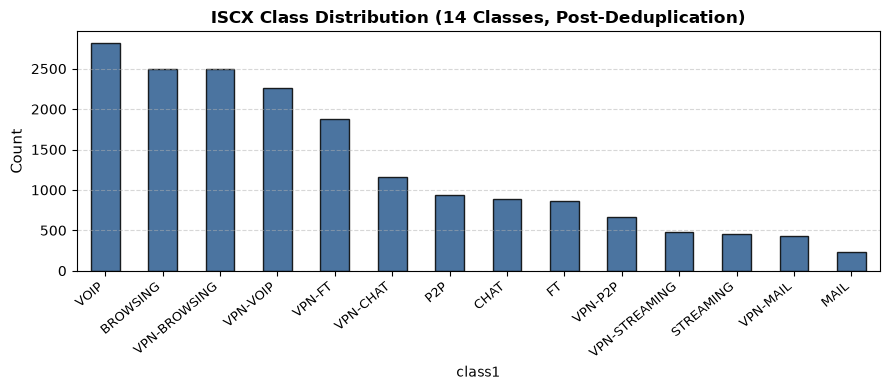

In [3]:
data, meta = arff.loadarff(data_path)
df = pd.DataFrame(data)
df['class1'] = df['class1'].apply(lambda x: x.decode('utf-8'))

initial_len = len(df)
df = df.drop_duplicates()
print(f"중복 제거: {initial_len} -> {len(df)} samples")

X = df.drop('class1', axis=1).values
y_labels = df['class1'].values

unique_classes = np.unique(y_labels)
class_map = {cls: i for i, cls in enumerate(unique_classes)}
y = np.array([class_map[cls] for cls in y_labels])

class_counts = df['class1'].value_counts()
print("\n--- Class Distribution (14 Classes) ---")
for cls_name, count in class_counts.items():
    print(f"{cls_name:15s}: {count:5d} ({count/len(df)*100:5.2f}%)")

# Stratified 60 / 20 / 20 Split (v1/v2 Locked Protocol)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

print("\n--- Split Partition Verification ---")
print(f"Train set: {X_train.shape[0]} samples (60%) [학습 전용]")
print(f"Val set:   {X_val.shape[0]} samples (20%) [검증 튜닝 전용 (Val Tuning ONLY)]")
print(f"Test set:  {X_test.shape[0]} samples (20%) [봉인됨 - 절대 접근 금지 (LOCKED)]")

assert len(X_train) == 10844, "Train split mismatch"
assert len(X_val) == 3615, "Val split mismatch"
assert len(X_test) == 3615, "Test split mismatch"

fig_dist = plt.figure(figsize=(9, 4))
class_counts.plot(kind='bar', color='#2b5c8f', edgecolor='black', alpha=0.85)
plt.title('ISCX Class Distribution (14 Classes, Post-Deduplication)', fontsize=12, fontweight='bold')
plt.ylabel('Count', fontsize=11)
plt.xticks(rotation=40, ha='right', fontsize=9)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 3. v2 특성 엔지니어링 (75차원) 및 지도 특성 선택 (38차원, Fit on Train Only)
비선형 로그 변환(`log1p`), 패킷당 바이트비, Flow IAT 변동계수(CV), Active/Idle 비율, 음수 플래그 등 도메인 특화 75차원 특성을 구축합니다.  
**Data Leakage 방지**: `RobustScaler` 및 `SelectFromModel` (ExtraTrees)은 **오직 Train 데이터에만 피팅**합니다.

In [4]:
def engineer_features(X_arr):
    log_part = np.log1p(np.maximum(X_arr, 0))
    bytes_per_pkt = np.where(X_arr[:, 9] > 0, X_arr[:, 10] / (X_arr[:, 9] + 1e-5), 0).reshape(-1, 1)
    fiat_biat_ratio = np.where(X_arr[:, 2] > 0, X_arr[:, 1] / (X_arr[:, 2] + 1e-5), 0).reshape(-1, 1)
    active_idle_ratio = np.where((X_arr[:, 16] + X_arr[:, 20]) > 0, X_arr[:, 16] / (X_arr[:, 16] + X_arr[:, 20] + 1e-5), 0).reshape(-1, 1)
    flowiat_cv = np.where(X_arr[:, 13] > 0, X_arr[:, 14] / (X_arr[:, 13] + 1e-5), 0).reshape(-1, 1)
    active_cv = np.where(X_arr[:, 16] > 0, X_arr[:, 18] / (X_arr[:, 16] + 1e-5), 0).reshape(-1, 1)
    idle_cv = np.where(X_arr[:, 20] > 0, X_arr[:, 22] / (X_arr[:, 20] + 1e-5), 0).reshape(-1, 1)
    neg_flags = (X_arr < 0).astype(float)
    return np.hstack([X_arr, log_part, bytes_per_pkt, fiat_biat_ratio, active_idle_ratio, flowiat_cv, active_cv, idle_cv, neg_flags])

# 75-dim Feature Engineering
X_tr_fe = engineer_features(X_train)
X_val_fe = engineer_features(X_val)

# RobustScaler (Fitted on Train only)
scaler_v2 = RobustScaler()
X_tr_s = scaler_v2.fit_transform(X_tr_fe)
X_val_s = scaler_v2.transform(X_val_fe)

# Supervised Feature Selection (SelectFromModel ExtraTrees fitted on Train only)
sel = SelectFromModel(ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1), threshold='median')
sel.fit(X_tr_s, y_train)

X_tr_sel = sel.transform(X_tr_s)
X_val_sel = sel.transform(X_val_s)

print(f"차원 확장 (Feature Expansion):  {X_train.shape[1]} -> {X_tr_fe.shape[1]} features")
print(f"선택 차원 (Selected Features): {X_tr_sel.shape[1]} informative features (Noise removed)")
assert X_tr_sel.shape[1] == 38, "Selected feature dimension must be 38"
assert X_val_sel.shape[1] == 38, "Val selected feature dimension must be 38"
print("Feature Engineering & Selection Protocol: PASS (Strict Fit on Train Only)")

차원 확장 (Feature Expansion):  23 -> 75 features
선택 차원 (Selected Features): 38 informative features (Noise removed)
Feature Engineering & Selection Protocol: PASS (Strict Fit on Train Only)


## 4. 기준 모델(Baseline RF & v1 Deep NN) 검증셋 3-Run 성능 기준치
비교 평가를 위해 v1/v2의 기준 모델인 Baseline Random Forest 및 v1 Deep Neural Network(MLP)의 검증셋 3-Run 성능을 측정합니다.

In [5]:
# Reference Benchmarks on Validation Set
scaler_base = StandardScaler()
X_tr_base = scaler_base.fit_transform(X_train)
X_val_base = scaler_base.transform(X_val)

seeds = [42, 1004, 2026]

# 1. Baseline RF (Default RF, StandardScaler, unweighted)
rf_val_accs, rf_val_f1s = [], []
for s in seeds:
    rf = RandomForestClassifier(random_state=s, n_jobs=-1)
    rf.fit(X_tr_base, y_train)
    p_rf = rf.predict(X_val_base)
    acc = accuracy_score(y_val, p_rf)
    f1 = f1_score(y_val, p_rf, average='macro')
    rf_val_accs.append(acc)
    rf_val_f1s.append(f1)
    print(f"[Baseline RF] Seed {s:4d} Val - Acc: {acc:.4f}, Macro-F1: {f1:.4f}")

rf_acc_m, rf_acc_s = np.mean(rf_val_accs), np.std(rf_val_accs, ddof=1)
rf_f1_m, rf_f1_s = np.mean(rf_val_f1s), np.std(rf_val_f1s, ddof=1)
print(f"[Baseline RF 3-Run Val] Acc: {rf_acc_m:.4f} ± {rf_acc_s:.4f}, Macro-F1: {rf_f1_m:.4f} ± {rf_f1_s:.4f}\n")

# 2. v1 Deep NN (MLP 256->128->64)
class V1NN(nn.Module):
    def __init__(self, in_features=23, num_classes=14):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.net(x)

v1_val_accs, v1_val_f1s = [], []
for s in seeds:
    torch.manual_seed(s)
    np.random.seed(s)
    train_ds = TensorDataset(torch.FloatTensor(X_tr_base), torch.LongTensor(y_train))
    train_ld = DataLoader(train_ds, batch_size=128, shuffle=True)
    
    m_v1 = V1NN(in_features=23, num_classes=len(unique_classes)).to(device)
    crit = nn.CrossEntropyLoss()
    opt = optim.Adam(m_v1.parameters(), lr=0.001)
    sch = optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=5)
    
    best_loss = float('inf')
    best_w = None
    patience_cnt = 0
    for epoch in range(35):
        m_v1.train()
        for bx, by in train_ld:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad()
            out = m_v1(bx)
            loss = crit(out, by)
            loss.backward()
            opt.step()
        m_v1.eval()
        with torch.no_grad():
            vo = m_v1(torch.FloatTensor(X_val_base).to(device))
            vl = crit(vo, torch.LongTensor(y_val).to(device)).item()
        sch.step(vl)
        if vl < best_loss:
            best_loss = vl
            best_w = copy.deepcopy(m_v1.state_dict())
            patience_cnt = 0
        else:
            patience_cnt += 1
            if patience_cnt >= 8:
                break
    m_v1.load_state_dict(best_w)
    m_v1.eval()
    with torch.no_grad():
        pred_v1 = torch.argmax(m_v1(torch.FloatTensor(X_val_base).to(device)), dim=1).cpu().numpy()
    acc = accuracy_score(y_val, pred_v1)
    f1 = f1_score(y_val, pred_v1, average='macro')
    v1_val_accs.append(acc)
    v1_val_f1s.append(f1)
    print(f"[v1 Deep NN]  Seed {s:4d} Val - Acc: {acc:.4f}, Macro-F1: {f1:.4f}")

v1_acc_m, v1_acc_s = np.mean(v1_val_accs), np.std(v1_val_accs, ddof=1)
v1_f1_m, v1_f1_s = np.mean(v1_val_f1s), np.std(v1_val_f1s, ddof=1)
print(f"[v1 Deep NN 3-Run Val] Acc: {v1_acc_m:.4f} ± {v1_acc_s:.4f}, Macro-F1: {v1_f1_m:.4f} ± {v1_f1_s:.4f}")

[Baseline RF] Seed   42 Val - Acc: 0.8578, Macro-F1: 0.8178


[Baseline RF] Seed 1004 Val - Acc: 0.8542, Macro-F1: 0.8157


[Baseline RF] Seed 2026 Val - Acc: 0.8548, Macro-F1: 0.8169
[Baseline RF 3-Run Val] Acc: 0.8556 ± 0.0019, Macro-F1: 0.8168 ± 0.0010



[v1 Deep NN]  Seed   42 Val - Acc: 0.6064, Macro-F1: 0.5055


[v1 Deep NN]  Seed 1004 Val - Acc: 0.5983, Macro-F1: 0.5149


[v1 Deep NN]  Seed 2026 Val - Acc: 0.6044, Macro-F1: 0.5151
[v1 Deep NN 3-Run Val] Acc: 0.6030 ± 0.0042, Macro-F1: 0.5118 ± 0.0055


## 5. FT-Transformer (Feature Tokenizer + Transformer) 아키텍처 설계
Gorishniy et al. (NeurIPS 2021)의 타뷸러 트랜스포머 아키텍처를 구현합니다.
1. **Feature Tokenizer**: 38개의 연속형 특성 $x_j$ 각각을 학습 가능한 선형 파라미터($W_j \in \mathbb{R}^d, b_j \in \mathbb{R}^d$)를 통해 $d$-차원 토큰 벡터 $e_j \in \mathbb{R}^d$로 사상합니다.
2. **[CLS] Token**: 분류를 위한 학습 가능한 요약 토큰 $e_{\text{CLS}} \in \mathbb{R}^d$을 특성 토큰 시퀀스 선두에 부착합니다.
3. **Transformer Encoder**: Pre-LayerNorm(`norm_first=True`) 구조의 Multi-Head Self-Attention 및 FeedForward 블록을 통해 특성 간 전역적 상호작용을 계산합니다.
4. **Classification Head**: `[CLS]` 토큰의 최종 계층 출력에 LayerNorm, Dropout, Linear 레이어를 적용하여 14개 클래스 로짓을 산출합니다.

In [6]:
class FeatureTokenizer(nn.Module):
    """수치형 특성을 개별적 학습 가능 임베딩 토큰으로 변환하는 Feature Tokenizer"""
    def __init__(self, num_features, d_token):
        super().__init__()
        self.weight = nn.Parameter(torch.Tensor(num_features, d_token))
        self.bias = nn.Parameter(torch.Tensor(num_features, d_token))
        nn.init.kaiming_uniform_(self.weight, a=np.sqrt(5))
        nn.init.zeros_(self.bias)
        
    def forward(self, x):
        # x: (B, num_features) -> (B, num_features, d_token)
        return x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)

class FTTransformer(nn.Module):
    """Tabular FT-Transformer 모델 아키텍처"""
    def __init__(self, num_features=38, num_classes=14, d_token=64, n_heads=4, n_layers=2, d_ff=128, dropout=0.1):
        super().__init__()
        self.tokenizer = FeatureTokenizer(num_features, d_token)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_token))
        nn.init.normal_(self.cls_token, std=0.02)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_token,
            nhead=n_heads,
            dim_feedforward=d_ff,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.head_norm = nn.LayerNorm(d_token)
        self.head = nn.Sequential(
            nn.Linear(d_token, d_token),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_token, num_classes)
        )
        
    def forward(self, x):
        B = x.size(0)
        tokens = self.tokenizer(x)                    # (B, 38, d_token)
        cls_tokens = self.cls_token.expand(B, -1, -1)  # (B, 1, d_token)
        x_seq = torch.cat([cls_tokens, tokens], dim=1) # (B, 39, d_token)
        
        out = self.transformer(x_seq)                  # (B, 39, d_token)
        cls_rep = self.head_norm(out[:, 0, :])          # (B, d_token)
        logits = self.head(cls_rep)                     # (B, num_classes)
        return logits

# Instantiate sample model to inspect parameter count
sample_model = FTTransformer(num_features=38, num_classes=14, d_token=64, n_heads=4, n_layers=2, d_ff=128, dropout=0.1)
total_params = sum(p.numel() for p in sample_model.parameters() if p.requires_grad)
print(f"FT-Transformer Architecture Summary:")
print(f" - Input Features:  38")
print(f" - Token Dimension: 64")
print(f" - Attention Heads: 4")
print(f" - Encoder Layers:  2 (Pre-LN)")
print(f" - FeedForward Dim: 128 (GELU)")
print(f" - Head Dropout:    0.1")
print(f" - Total Trainable Parameters: {total_params:,}")

FT-Transformer Architecture Summary:
 - Input Features:  38
 - Token Dimension: 64
 - Attention Heads: 4
 - Encoder Layers:  2 (Pre-LN)
 - FeedForward Dim: 128 (GELU)
 - Head Dropout:    0.1
 - Total Trainable Parameters: 77,070


## 6. 3-Seed 검증셋 학습 및 성능 평가 (Validation Tuning ONLY)
**Locked Protocol**: 시드 `[42, 1004, 2026]`에 대해 검증셋(Val)으로만 모델 성능을 측정합니다.  
소수 클래스 탐지 성능 제고를 위해 클래스 가중치가 반영된 Cross-Entropy 손실함수와 AdamW 옵티마이저, Cosine Annealing 스케줄러를 적용합니다.  
최종 3-Run 성능(표본표준편차 $n=3$, $ddof=1$)을 산출하고 `val_metrics.json` 파일로 저장합니다.

In [7]:
# Compute smooth class weights to balance 14 classes without over-penalizing majority classes
cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
cw_smooth = (cw ** 0.5)
cw_tensor = torch.FloatTensor(cw_smooth).to(device)

seeds = [42, 1004, 2026]
model_cfg = {'d_token': 64, 'n_heads': 4, 'n_layers': 2, 'd_ff': 128, 'dropout': 0.1}
train_cfg = {'batch_size': 128, 'lr': 1e-3, 'weight_decay': 1e-4, 'epochs': 25}

ft_val_accs, ft_val_f1s = [], []
per_seed_results = {}
histories = {}
best_val_predictions = {}

val_x_t = torch.FloatTensor(X_val_sel).to(device)
val_y_t = torch.LongTensor(y_val).to(device)

print("="*75)
print("              FT-TRANSFORMER 3-SEED VALIDATION TUNING")
print("="*75)

for s in seeds:
    torch.manual_seed(s)
    np.random.seed(s)
    
    train_ds = TensorDataset(torch.FloatTensor(X_tr_sel), torch.LongTensor(y_train))
    train_ld = DataLoader(train_ds, batch_size=train_cfg['batch_size'], shuffle=True)
    
    model = FTTransformer(num_features=38, num_classes=14, **model_cfg).to(device)
    criterion = nn.CrossEntropyLoss(weight=cw_tensor)
    optimizer = optim.AdamW(model.parameters(), lr=train_cfg['lr'], weight_decay=train_cfg['weight_decay'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=train_cfg['epochs'], eta_min=1e-5)
    
    best_f1 = 0.0
    best_acc = 0.0
    best_w = None
    best_preds = None
    
    hist = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
    t0 = time.time()
    
    for epoch in range(train_cfg['epochs']):
        model.train()
        running_loss = 0.0
        for bx, by in train_ld:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(by)
        scheduler.step()
        train_loss = running_loss / len(X_train)
        
        model.eval()
        with torch.no_grad():
            v_logits = model(val_x_t)
            v_preds = torch.argmax(v_logits, dim=1).cpu().numpy()
            v_loss = criterion(v_logits, val_y_t).item()
            
        acc = accuracy_score(y_val, v_preds)
        f1 = f1_score(y_val, v_preds, average='macro')
        
        hist['train_loss'].append(train_loss)
        hist['val_loss'].append(v_loss)
        hist['val_acc'].append(acc)
        hist['val_f1'].append(f1)
        
        if f1 > best_f1:
            best_f1 = f1
            best_acc = acc
            best_w = copy.deepcopy(model.state_dict())
            best_preds = v_preds
            
    elapsed = time.time() - t0
    ft_val_accs.append(best_acc)
    ft_val_f1s.append(best_f1)
    histories[s] = hist
    best_val_predictions[s] = best_preds
    
    per_seed_results[str(s)] = {
        'val_accuracy': round(float(best_acc), 6),
        'val_macro_f1': round(float(best_f1), 6),
        'elapsed_seconds': round(float(elapsed), 2)
    }
    print(f"[FT-Transformer] Seed {s:4d} Val - Best Acc: {best_acc:.4f}, Best Macro-F1: {best_f1:.4f} (Elapsed: {elapsed:.1f}s)")

ft_acc_m, ft_acc_s = float(np.mean(ft_val_accs)), float(np.std(ft_val_accs, ddof=1))
ft_f1_m, ft_f1_s = float(np.mean(ft_val_f1s)), float(np.std(ft_val_f1s, ddof=1))

print("="*75)
print(f"FT-Transformer 3-Run Val Acc:      {ft_acc_m:.4f} ± {ft_acc_s:.4f} (ddof=1)")
print(f"FT-Transformer 3-Run Val Macro-F1: {ft_f1_m:.4f} ± {ft_f1_s:.4f} (ddof=1)")
print("="*75)

# Comparison Table across Models on Validation Set
comp_df = pd.DataFrame({
    'Model Architecture': ['1. v1 Deep NN (MLP)', '2. Baseline Random Forest', '3. Lane C FT-Transformer (Ours)'],
    'Seed 42 (Acc)': [v1_val_accs[0], rf_val_accs[0], ft_val_accs[0]],
    'Seed 42 (F1)':  [v1_val_f1s[0], rf_val_f1s[0], ft_val_f1s[0]],
    'Seed 1004 (Acc)': [v1_val_accs[1], rf_val_accs[1], ft_val_accs[1]],
    'Seed 1004 (F1)':  [v1_val_f1s[1], rf_val_f1s[1], ft_val_f1s[1]],
    'Seed 2026 (Acc)': [v1_val_accs[2], rf_val_accs[2], ft_val_accs[2]],
    'Seed 2026 (F1)':  [v1_val_f1s[2], rf_val_f1s[2], ft_val_f1s[2]],
    'Mean Val Acc': [v1_acc_m, rf_acc_m, ft_acc_m],
    'Std Val Acc':  [v1_acc_s, rf_acc_s, ft_acc_s],
    'Mean Val F1':  [v1_f1_m, rf_f1_m, ft_f1_m],
    'Std Val F1':   [v1_f1_s, rf_f1_s, ft_f1_s]
})

print("\n" + "="*85)
print("             VALIDATION SET 3-RUN COMPARISON BENCHMARK (ddof=1)")
print("="*85)
print(comp_df.to_string(index=False))
print("="*85)
print(f"Gain vs v1 Deep NN:  Val Acc +{(ft_acc_m - v1_acc_m)*100:+.2f}%p, Val Macro-F1 +{(ft_f1_m - v1_f1_m)*100:+.2f}%p")
print(f"Gain vs Baseline RF: Val Acc +{(ft_acc_m - rf_acc_m)*100:+.2f}%p, Val Macro-F1 +{(ft_f1_m - rf_f1_m)*100:+.2f}%p")

# Save validation metrics JSON
val_metrics_payload = {
    'lane': 'Lane C',
    'architecture': 'FT-Transformer Style',
    'model_family': 'transformer',
    'protocol': 'v2 75-dim FE + 38-feature selection fit TRAIN only',
    'split': '60/20/20 Stratified (Val tuning only, Test untouched)',
    'seeds': seeds,
    'per_seed': per_seed_results,
    'summary': {
        'val_accuracy_mean': round(ft_acc_m, 6),
        'val_accuracy_std': round(ft_acc_s, 6),
        'val_macro_f1_mean': round(ft_f1_m, 6),
        'val_macro_f1_std': round(ft_f1_s, 6),
        'ddof': 1
    },
    'gain_vs_v1_nn': {
        'val_accuracy_gain': round(ft_acc_m - v1_acc_m, 6),
        'val_macro_f1_gain': round(ft_f1_m - v1_f1_m, 6)
    },
    'gain_vs_baseline_rf': {
        'val_accuracy_gain': round(ft_acc_m - rf_acc_m, 6),
        'val_macro_f1_gain': round(ft_f1_m - rf_f1_m, 6)
    },
    'config': {
        'model': model_cfg,
        'train': train_cfg
    },
    'timestamp': time.strftime('%Y-%m-%dT%H:%M:%S%z')
}

with open('val_metrics.json', 'w', encoding='utf-8') as f:
    json.dump(val_metrics_payload, f, indent=2, ensure_ascii=False)
print("\nSaved val_metrics.json successfully.")

              FT-TRANSFORMER 3-SEED VALIDATION TUNING


[FT-Transformer] Seed   42 Val - Best Acc: 0.8382, Best Macro-F1: 0.7991 (Elapsed: 400.5s)


[FT-Transformer] Seed 1004 Val - Best Acc: 0.8387, Best Macro-F1: 0.7932 (Elapsed: 104.1s)


[FT-Transformer] Seed 2026 Val - Best Acc: 0.8418, Best Macro-F1: 0.8029 (Elapsed: 106.2s)
FT-Transformer 3-Run Val Acc:      0.8396 ± 0.0019 (ddof=1)
FT-Transformer 3-Run Val Macro-F1: 0.7984 ± 0.0048 (ddof=1)

             VALIDATION SET 3-RUN COMPARISON BENCHMARK (ddof=1)
             Model Architecture  Seed 42 (Acc)  Seed 42 (F1)  Seed 1004 (Acc)  Seed 1004 (F1)  Seed 2026 (Acc)  Seed 2026 (F1)  Mean Val Acc  Std Val Acc  Mean Val F1  Std Val F1
            1. v1 Deep NN (MLP)       0.606362      0.505460         0.598340        0.514924         0.604426        0.515131      0.603043     0.004186     0.511838    0.005525
      2. Baseline Random Forest       0.857815      0.817767         0.854219        0.815736         0.854772        0.816867      0.855602     0.001936     0.816790    0.001018
3. Lane C FT-Transformer (Ours)       0.838174      0.799092         0.838728        0.793249         0.841770        0.802851      0.839557     0.001936     0.798397    0.004838
Gain vs 

## 7. 검증셋 성능 시각화 및 오차 행렬 분석
1. **모델별 검증 성능 비교 (Mean ± SD 오차막대 포함)**
2. **FT-Transformer Seed 42 검증 오차 행렬 (Confusion Matrix)**
3. **에폭별 학습 및 검증 곡선 (Loss & Macro-F1 Trajectory)**

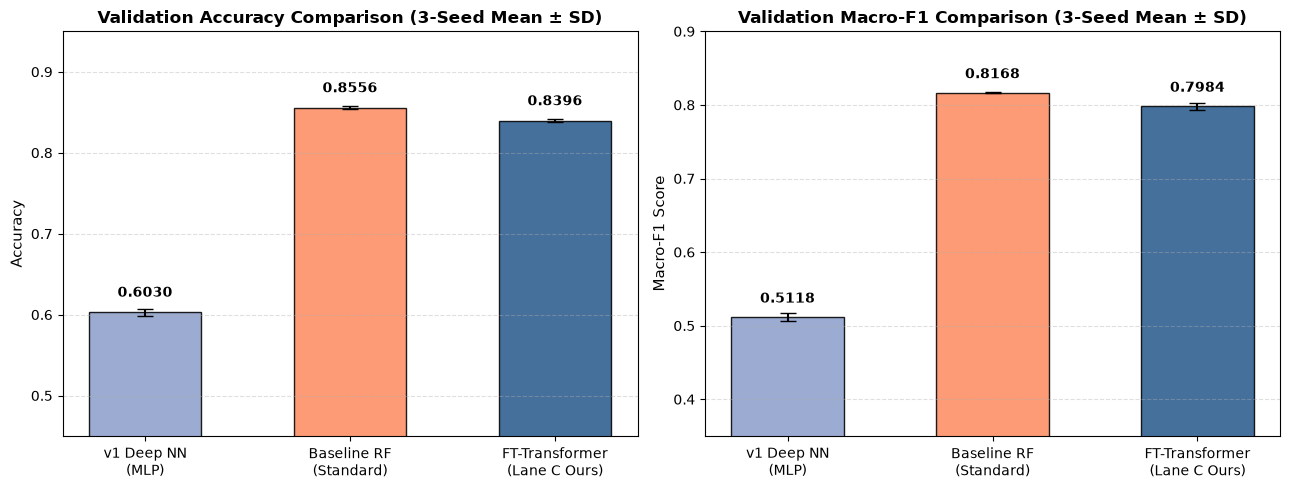

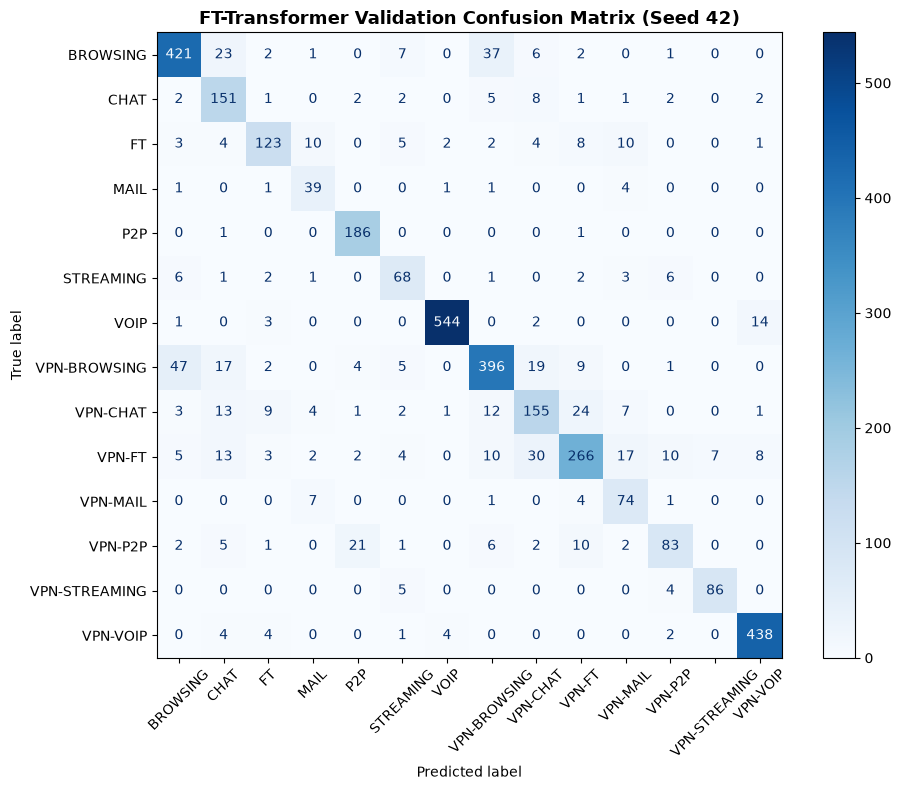

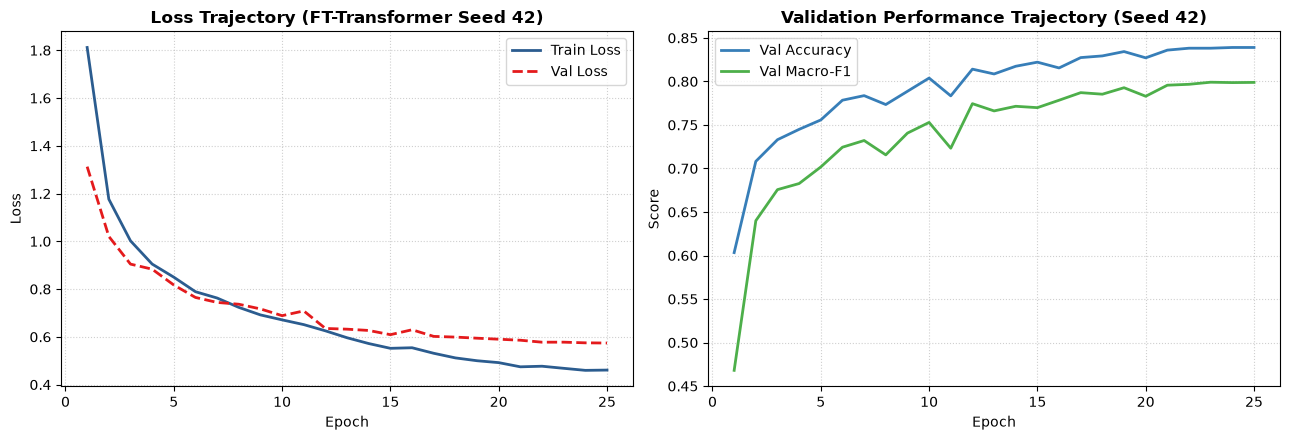

In [8]:
# 1. Performance Comparison Bar Chart with Error Bars (ddof=1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

models = ['v1 Deep NN\n(MLP)', 'Baseline RF\n(Standard)', 'FT-Transformer\n(Lane C Ours)']
acc_means = [v1_acc_m, rf_acc_m, ft_acc_m]
acc_stds = [v1_acc_s, rf_acc_s, ft_acc_s]
f1_means = [v1_f1_m, rf_f1_m, ft_f1_m]
f1_stds = [v1_f1_s, rf_f1_s, ft_f1_s]

colors = ['#8da0cb', '#fc8d62', '#2b5c8f']

# Accuracy Plot
bars1 = ax1.bar(models, acc_means, yerr=acc_stds, capsize=6, color=colors, edgecolor='black', alpha=0.88, width=0.55)
ax1.set_title('Validation Accuracy Comparison (3-Seed Mean ± SD)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Accuracy', fontsize=11)
ax1.set_ylim(0.45, 0.95)
ax1.grid(axis='y', linestyle='--', alpha=0.4)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.015, f"{yval:.4f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

# Macro-F1 Plot
bars2 = ax2.bar(models, f1_means, yerr=f1_stds, capsize=6, color=colors, edgecolor='black', alpha=0.88, width=0.55)
ax2.set_title('Validation Macro-F1 Comparison (3-Seed Mean ± SD)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Macro-F1 Score', fontsize=11)
ax2.set_ylim(0.35, 0.90)
ax2.grid(axis='y', linestyle='--', alpha=0.4)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.015, f"{yval:.4f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Confusion Matrix Display on Validation Set (Seed 42)
fig_cm, ax_cm = plt.subplots(figsize=(10, 8))
cm = confusion_matrix(y_val, best_val_predictions[42])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_classes)
disp.plot(ax=ax_cm, cmap='Blues', colorbar=True, xticks_rotation=45)
ax_cm.set_title('FT-Transformer Validation Confusion Matrix (Seed 42)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Learning Trajectory Curves (Seed 42)
h42 = histories[42]
fig_curve, (ax_l, ax_f) = plt.subplots(1, 2, figsize=(13, 4.5))

epochs_arr = range(1, len(h42['train_loss']) + 1)
ax_l.plot(epochs_arr, h42['train_loss'], label='Train Loss', color='#2b5c8f', lw=2)
ax_l.plot(epochs_arr, h42['val_loss'], label='Val Loss', color='#e41a1c', lw=2, linestyle='--')
ax_l.set_title('Loss Trajectory (FT-Transformer Seed 42)', fontsize=12, fontweight='bold')
ax_l.set_xlabel('Epoch', fontsize=10)
ax_l.set_ylabel('Loss', fontsize=10)
ax_l.grid(True, linestyle=':', alpha=0.6)
ax_l.legend()

ax_f.plot(epochs_arr, h42['val_acc'], label='Val Accuracy', color='#377eb8', lw=2)
ax_f.plot(epochs_arr, h42['val_f1'], label='Val Macro-F1', color='#4daf4a', lw=2)
ax_f.set_title('Validation Performance Trajectory (Seed 42)', fontsize=12, fontweight='bold')
ax_f.set_xlabel('Epoch', fontsize=10)
ax_f.set_ylabel('Score', fontsize=10)
ax_f.grid(True, linestyle=':', alpha=0.6)
ax_f.legend()

plt.tight_layout()
plt.show()